# Unidad IV: clustering y PCA

## Objetivo

Agrupar sesiones por patrones de navegación sin usar `Revenue` para formar los grupos y reducir la dimensionalidad con PCA para visualizar los patrones. Se documenta el escalado, el criterio de selección de K, el tamaño de los grupos y la varianza explicada.

Se usan variables conductuales numéricas; los códigos de navegador/sistema/región/tráfico y la etiqueta de compra se excluyen del clustering. `Revenue` se consulta después para describir cada grupo, no participa en el ajuste.


In [2]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline

RAIZ_PROYECTO = Path.cwd()
if RAIZ_PROYECTO.name == 'notebooks':
    RAIZ_PROYECTO = RAIZ_PROYECTO.parent
ruta = RAIZ_PROYECTO / 'data' / 'processed' / 'online_shoppers_intention_clean.csv'
if not ruta.exists():
    raise FileNotFoundError('No se encontró el dataset procesado.')

datos = pd.read_csv(ruta)
variables_cluster = [
    'Administrative', 'Administrative_Duration', 'Informational',
    'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'
]
X = datos[variables_cluster]
escalador = RobustScaler()
X_escalado = escalador.fit_transform(X)
print(f'Sesiones analizadas: {len(X):,}')
print(f'Variables para agrupar: {len(variables_cluster)}')
print('Revenue se excluye del ajuste y se reserva para describir los clusters.')


Sesiones analizadas: 12,205
Variables para agrupar: 10
Revenue se excluye del ajuste y se reserva para describir los clusters.


## 1. Elegir una cantidad candidata de clusters

Se prueban valores de K entre 2 y 6. Se comparan la inercia (compactación interna, menor tiende a ser mejor) y el coeficiente silhouette (separación/cohesión, mayor tiende a ser mejor). El silhouette se calcula sobre una muestra reproducible de hasta 3,000 sesiones para controlar el costo de las distancias.


In [4]:
resultados_k = []
for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas_k = modelo_k.fit_predict(X_escalado)
    silhouette = silhouette_score(
        X_escalado, etiquetas_k,
        sample_size=min(3000, len(X_escalado)), random_state=42
    )
    resultados_k.append({
        'K': k,
        'Inercia': modelo_k.inertia_,
        'Silhouette_muestreado': silhouette,
    })

tabla_k = pd.DataFrame(resultados_k)
print(tabla_k.round(4).to_string(index=False))
mejor_k = int(tabla_k.sort_values('Silhouette_muestreado', ascending=False).iloc[0]['K'])
print()
print(f'K candidata con mayor silhouette dentro del rango probado: {mejor_k}')


 K      Inercia  Silhouette_muestreado
 2 8.475215e+07                 0.9343
 3 4.190172e+07                 0.8910
 4 2.564922e+07                 0.8700
 5 1.754686e+07                 0.8425
 6 1.395813e+07                 0.8109

K candidata con mayor silhouette dentro del rango probado: 2


## 2. Ajustar K-Means y caracterizar los grupos

Se vuelve a ajustar K-Means con la K candidata sobre las 12,205 sesiones. La tabla de medianas permite describir los patrones de navegación; la tasa de `Revenue=True` ayuda a comparar los grupos después del ajuste, sin convertirla en entrada del algoritmo.


In [6]:
modelo_kmeans = KMeans(n_clusters=mejor_k, n_init=20, random_state=42)
clusters = modelo_kmeans.fit_predict(X_escalado)
datos_cluster = datos.copy()
datos_cluster['Cluster'] = clusters

resumen_clusters = datos_cluster.groupby('Cluster').agg(
    Sesiones=('Revenue', 'size'),
    TasaCompra=('Revenue', 'mean'),
    Administrative_mediana=('Administrative', 'median'),
    ProductRelated_mediana=('ProductRelated', 'median'),
    DuracionProducto_mediana=('ProductRelated_Duration', 'median'),
    PageValues_mediana=('PageValues', 'median'),
).round(3)
print(resumen_clusters.to_string())
print()
print('Sesiones asignadas:', int(resumen_clusters['Sesiones'].sum()))

carpeta_modelos = RAIZ_PROYECTO / 'modelos'
carpeta_modelos.mkdir(exist_ok=True)
carpeta_datos = RAIZ_PROYECTO / 'data' / 'processed'
carpeta_datos.mkdir(parents=True, exist_ok=True)
joblib.dump(Pipeline([
    ('escalador', RobustScaler()),
    ('kmeans', KMeans(n_clusters=mejor_k, n_init=20, random_state=42)),
]), carpeta_modelos / 'kmeans_sesiones.joblib', compress=3)
datos_cluster.to_csv(carpeta_datos / 'sesiones_clusterizadas.csv', index=False)
tabla_k.to_csv(carpeta_modelos / 'metricas_kmeans.csv', index=False)


         Sesiones  TasaCompra  Administrative_mediana  ProductRelated_mediana  DuracionProducto_mediana  PageValues_mediana
Cluster                                                                                                                    
0           11949       0.154                     1.0                    18.0                   591.167               0.000
1             256       0.277                     5.0                    57.0                  2362.876               1.428

Sesiones asignadas: 12205


## 3. PCA para visualizar y resumir variación

PCA se ajusta sobre las mismas variables escaladas que K-Means. Se reporta cuánta varianza acumulan los dos primeros componentes. El plano de dos componentes sirve para visualizar; no se asume que preserve toda la estructura del espacio original.


Varianza explicada por PC1: 98.204%
Varianza explicada por PC2: 1.708%
Varianza acumulada en 2 componentes: 99.912%


C:\Users\chave\REC_ECDB_2026_ChavezMolina_Byron\notebooks\04_clustering_pca.ipynb cell 8:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


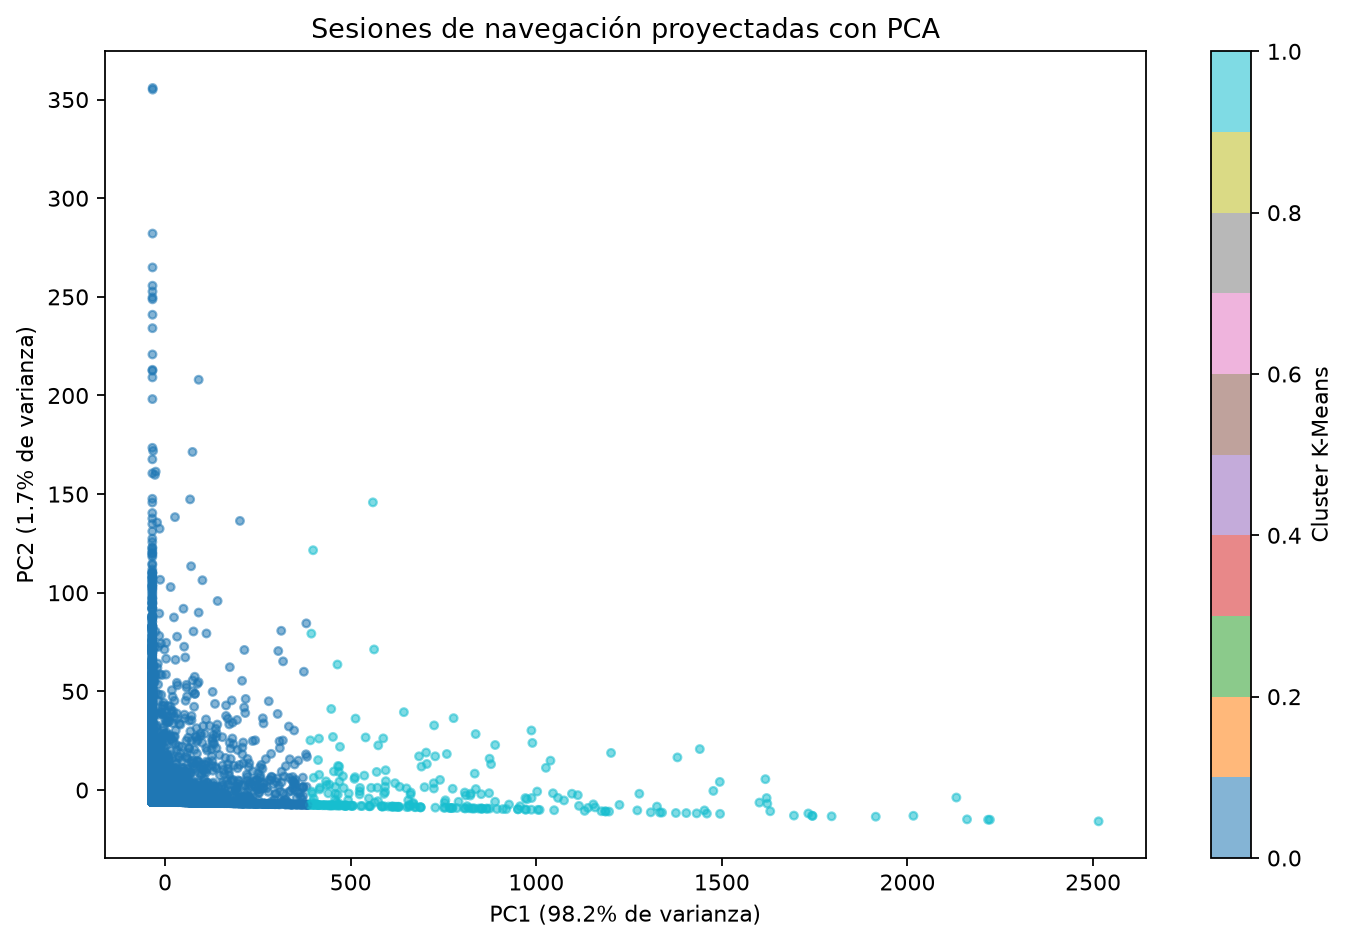

In [8]:
pca_2d = PCA(n_components=2, random_state=42)
coordenadas = pca_2d.fit_transform(X_escalado)
varianza = pca_2d.explained_variance_ratio_
print(f'Varianza explicada por PC1: {varianza[0]:.3%}')
print(f'Varianza explicada por PC2: {varianza[1]:.3%}')
print(f'Varianza acumulada en 2 componentes: {varianza.sum():.3%}')

carpeta_docs = RAIZ_PROYECTO / 'docs'
carpeta_docs.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(
    coordenadas[:, 0], coordenadas[:, 1], c=clusters,
    cmap='tab10', s=12, alpha=0.55
)
ax.set_title('Sesiones de navegación proyectadas con PCA')
ax.set_xlabel(f'PC1 ({varianza[0]:.1%} de varianza)')
ax.set_ylabel(f'PC2 ({varianza[1]:.1%} de varianza)')
fig.colorbar(scatter, ax=ax, label='Cluster K-Means')
fig.tight_layout()
fig.savefig(carpeta_docs / 'pca_clusters.png', dpi=160, bbox_inches='tight')
plt.show()

joblib.dump(pca_2d, carpeta_modelos / 'pca_sesiones.joblib', compress=3)
pd.DataFrame({
    'PC1': coordenadas[:, 0],
    'PC2': coordenadas[:, 1],
    'Cluster': clusters,
    'Revenue': datos['Revenue'].astype(int),
}).to_csv(carpeta_datos / 'coordenadas_pca.csv', index=False)
pd.DataFrame({
    'Componente': ['PC1', 'PC2'],
    'VarianzaExplicada': varianza,
    'VarianzaAcumulada': np.cumsum(varianza),
}).to_csv(carpeta_modelos / 'varianza_pca.csv', index=False)


## Interpretación y límites

- Compara la silhouette, la inercia y el tamaño de los grupos; no existe una K universalmente correcta.
- Usa las medianas de navegación para describir el comportamiento de cada cluster y su tasa de compra como perfil posterior.
- PCA es una proyección: si los dos primeros componentes explican poca varianza, el gráfico bidimensional no representa bien todas las diferencias.
- Las categorías `Other` y las sesiones extremas pueden influir en los grupos. La estandarización robusta reduce la influencia de escalas y valores extremos, pero no los elimina.

El notebook guarda asignaciones, métricas y modelos en `data/processed/` y `modelos/`; la imagen se guarda en `docs/pca_clusters.png`.
